# Exploración de datos

Objetivo: entender el dataset limpio y encontrar los patrones asociados a la deserción.

La pregunta de negocio prioriza estudiantes **al finalizar el primer semestre**, así que las variables del 2º semestre no estarían disponibles al predecir (ver sección 7).

Se trabaja con dos vistas del target: `Target` (3 clases, como está en el informe) y `dropout` (1 = deserción, 0 = graduado o matriculado), que es la que interesa para priorizar.

## 0. Carga de datos y target

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

In [2]:
# Paleta: azul = no deserción, naranja = deserción, aqua = tercera clase
AZUL, NARANJA, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
TINTA, GRIS, GRILLA = "#0b0b0b", "#898781", "#e1e0d9"
COLOR_TARGET = {"Dropout": NARANJA, "Enrolled": AQUA, "Graduate": AZUL}
MAPA_DIVERGENTE = LinearSegmentedColormap.from_list("div", [AZUL, "#f0efec", NARANJA])

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA, "text.color": TINTA,
    "xtick.color": GRIS, "ytick.color": GRIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRILLA, "grid.linewidth": 0.6,
    "axes.titlesize": 12, "axes.titleweight": "bold", "font.size": 10,
})

In [3]:
# Versión limpia en DVC (md5 f210546f...), separada por comas
df = pd.read_csv("data/students_dropout.csv")
# "Daytime/evening attendance" trae un tab al final del nombre en el archivo original
df.columns = df.columns.str.strip()
print(df.shape)
df.head()

(4424, 41)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target,estado_1st,estado_2nd,es_adulto,tasa_aprob_1st,tasa_aprob_2nd
0,1,17,5,171,1,1,122.0,1,19,-1,5,9,127.3,1,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout,no_inscrito,no_inscrito,0,0.000000,0.000000
1,1,-1,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate,normal,normal,0,1.000000,1.000000
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout,inscrito_sin_eval,inscrito_sin_eval,0,0.000000,0.000000
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate,normal,normal,0,1.000000,0.833333
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate,normal,normal,1,0.833333,1.000000


In [4]:
# El CSV no conserva los dtypes: se vuelven a declarar las categóricas de la limpieza
cat_cols = ["Marital status", "Application mode", "Course", "Previous qualification",
            "Nacionality", "Mother's qualification", "Father's qualification",
            "Mother's occupation", "Father's occupation"]
df[cat_cols] = df[cat_cols].astype("category")

# Target binario: deserción vs. resto (se conserva Target para la vista de 3 clases)
df["dropout"] = (df["Target"] == "Dropout").astype(int)
TASA_GLOBAL = df["dropout"].mean()

print("Nulos:", df.isna().sum().sum(), "| Duplicados:", df.duplicated().sum())
print(f"Tasa global de deserción: {TASA_GLOBAL:.1%}")

Nulos: 0 | Duplicados: 0
Tasa global de deserción: 32.1%


In [5]:
# Grupos de variables usados en todo el notebook
binarias = [c for c in df.columns
            if df[c].nunique() == 2 and c not in cat_cols + ["dropout"]]
estados = ["estado_1st", "estado_2nd"]
numericas = [c for c in df.select_dtypes("number").columns
             if c not in binarias + ["dropout"]]
print("Binarias:", binarias)
print("Numéricas:", len(numericas), "| Categóricas:", len(cat_cols) + len(estados))

Binarias: ['Daytime/evening attendance', 'Displaced', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International', 'es_adulto']
Numéricas: 21 | Categóricas: 11


## 1. Panorama del dataset

### 1.1 Diccionario de variables por grupo

In [6]:
grupos = {
    "Demográficas": ["Marital status", "Gender", "Age at enrollment", "Nacionality",
                     "International", "Displaced"],
    "Socioeconómicas": ["Mother's qualification", "Father's qualification", "Mother's occupation",
                        "Father's occupation", "Debtor", "Tuition fees up to date",
                        "Scholarship holder"],
    "Ingreso": ["Application mode", "Application order", "Course", "Daytime/evening attendance",
                "Previous qualification", "Previous qualification (grade)", "Admission grade"],
    "Académicas 1er semestre": [c for c in df.columns if "1st sem" in c],
    "Académicas 2º semestre": [c for c in df.columns if "2nd sem" in c],
    "Macroeconómicas": ["Unemployment rate", "Inflation rate", "GDP"],
    "Creadas en la limpieza": ["estado_1st", "estado_2nd", "es_adulto",
                               "tasa_aprob_1st", "tasa_aprob_2nd"],
}
diccionario = pd.DataFrame(
    [(g, c, str(df[c].dtype), df[c].nunique()) for g, cols in grupos.items() for c in cols],
    columns=["grupo", "variable", "tipo", "valores_unicos"],
)
print(diccionario.groupby("grupo", sort=False).size())
diccionario

grupo
Demográficas               6
Socioeconómicas            7
Ingreso                    7
Académicas 1er semestre    6
Académicas 2º semestre     6
Macroeconómicas            3
Creadas en la limpieza     5
dtype: int64


,grupo,variable,tipo,valores_unicos
0,Demográficas,Marital status,category,4
1,Demográficas,Gender,int64,2
2,Demográficas,Age at enrollment,int64,46
3,Demográficas,Nacionality,category,2
4,Demográficas,International,int64,2
5,Demográficas,Displaced,int64,2
6,Socioeconómicas,Mother's qualification,category,9
7,Socioeconómicas,Father's qualification,category,8
8,Socioeconómicas,Mother's occupation,category,11
9,Socioeconómicas,Father's occupation,category,13


### 1.2 Balance de clases

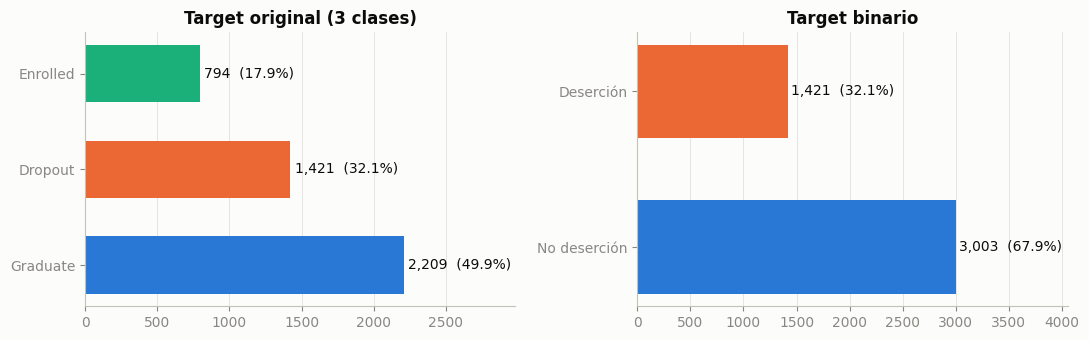

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

conteo = df["Target"].value_counts()
axes[0].barh(conteo.index, conteo.values, color=[COLOR_TARGET[c] for c in conteo.index], height=0.6)
axes[0].set_title("Target original (3 clases)")

binario = df["dropout"].map({1: "Deserción", 0: "No deserción"}).value_counts()
axes[1].barh(binario.index, binario.values,
             color=binario.index.map({"Deserción": NARANJA, "No deserción": AZUL}), height=0.6)
axes[1].set_title("Target binario")

for ax, serie in [(axes[0], conteo), (axes[1], binario)]:
    for i, v in enumerate(serie.values):
        ax.text(v + 30, i, f"{v:,}  ({v / len(df):.1%})", va="center", color=TINTA)
    ax.set_xlim(0, serie.max() * 1.35)
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Hallazgos**

- El dataset limpio tiene 4.424 estudiantes y 40 variables predictoras: 35 originales tras la limpieza más 5 creadas. A eso se suman `Target` y el `dropout` creado aquí. Están agrupadas en 7 bloques.
- **Desbalance moderado:** 32,1% deserción frente a 67,9% no deserción. En la vista de 3 clases, `Enrolled` es la minoritaria (17,9%).
- **Implicación para el modelo:** un modelo que nunca predice deserción ya acierta el 67,9%, así que la *accuracy* engaña. Conviene usar partición estratificada, `class_weight` o remuestreo, y métricas centradas en la clase de interés (recall y precisión de deserción, PR-AUC).

## 2. Análisis univariado

### 2.1 Variables numéricas

In [8]:
resumen_num = pd.DataFrame({
    "media": df[numericas].mean(),
    "mediana": df[numericas].median(),
    "min": df[numericas].min(),
    "max": df[numericas].max(),
    "asimetria": df[numericas].skew(),
    "% ceros": (df[numericas] == 0).mean() * 100,
    "valores_unicos": df[numericas].nunique(),
}).round(2)
resumen_num.sort_values("asimetria", key=abs, ascending=False)

,media,mediana,min,max,asimetria,% ceros,valores_unicos
Curricular units 1st sem (without evaluations),0.14,0.00,0.00,12.00,8.21,93.35,11
Curricular units 2nd sem (without evaluations),0.15,0.00,0.00,12.00,7.27,93.63,10
Curricular units 2nd sem (credited),0.54,0.00,0.00,19.00,4.63,88.02,19
Curricular units 1st sem (credited),0.71,0.00,0.00,20.00,4.17,86.96,21
Age at enrollment,23.27,20.00,17.00,70.00,2.05,0.00,46
Application order,1.73,1.00,0.00,9.00,1.88,0.02,8
Curricular units 1st sem (enrolled),6.27,6.00,0.00,26.00,1.62,4.07,23
Curricular units 1st sem (grade),10.64,12.29,0.00,18.88,-1.57,16.23,805
Curricular units 2nd sem (grade),10.23,12.20,0.00,18.57,-1.31,19.67,786
tasa_aprob_1st,0.70,0.83,0.00,1.00,-1.01,16.23,61


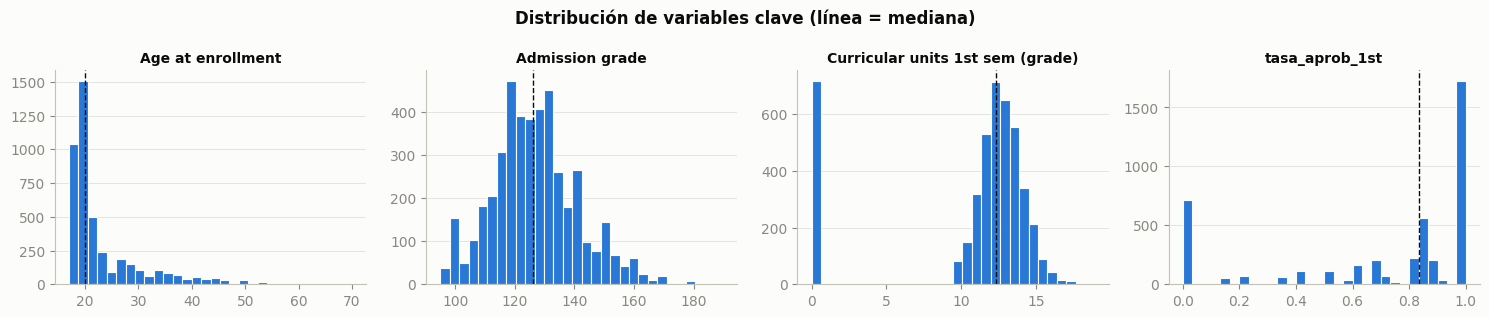

In [9]:
claves = ["Age at enrollment", "Admission grade", "Curricular units 1st sem (grade)", "tasa_aprob_1st"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, c in zip(axes, claves):
    ax.hist(df[c], bins=30, color=AZUL, edgecolor="#fcfcfb", linewidth=0.8)
    ax.axvline(df[c].median(), color=TINTA, linewidth=1, linestyle="--")
    ax.set_title(c, fontsize=10)
    ax.grid(axis="x", visible=False)
fig.suptitle("Distribución de variables clave (línea = mediana)", fontweight="bold")
plt.tight_layout()
plt.show()

**Hallazgos**

- **Edad de ingreso:** fuertemente asimétrica (asimetría 2,05). La mediana es 20 años, pero hay una cola larga hasta 70. Es una población mayoritariamente joven con un grupo relevante de adultos.
- **Nota y tasa de aprobación del 1er semestre:** el 16,2% tiene valor 0. Es exactamente el mismo grupo que no aprobó ninguna materia, así que en ese tramo la nota y la tasa dicen lo mismo. Fuera de los ceros, la nota se concentra entre 11 y 14.
- **`credited` y `without evaluations`:** más del 86% son ceros en ambos semestres, con muy poca variación.
- **`Admission grade`:** es casi simétrica (95 a 190, mediana 126) y no presenta problemas.

### 2.2 Variables categóricas y binarias

In [10]:
# Peso de la categoría -1 ("otros", agrupada en la limpieza) y de la categoría más frecuente
resumen_cat = pd.DataFrame({
    "categorias": [df[c].nunique() for c in cat_cols + estados],
    "% moda": [df[c].value_counts(normalize=True).iloc[0] * 100 for c in cat_cols + estados],
    "% otros (-1)": [(df[c] == -1).mean() * 100 for c in cat_cols + estados],
}, index=cat_cols + estados).round(1)
resumen_cat

,categorias,% moda,% otros (-1)
Marital status,4,88.6,0.8
Application mode,10,38.6,3.1
Course,17,17.3,0.3
Previous qualification,6,84.0,3.5
Nacionality,2,97.5,2.5
Mother's qualification,9,24.2,3.0
Father's qualification,8,27.3,4.0
Mother's occupation,11,35.6,3.4
Father's occupation,13,22.8,2.5
estado_1st,4,83.8,0.0


In [11]:
(df[binarias].mean() * 100).round(1).sort_values().to_frame("% con valor 1")

,% con valor 1
International,2.5
Debtor,11.4
Scholarship holder,24.8
es_adulto,25.7
Gender,35.2
Displaced,54.8
Tuition fees up to date,88.1
Daytime/evening attendance,89.1


In [12]:
# Variables macroeconómicas: pocos valores distintos
df[["Unemployment rate", "Inflation rate", "GDP"]].drop_duplicates().sort_values("Unemployment rate")

,Unemployment rate,Inflation rate,GDP
25,7.6,2.6,0.32
9,8.9,1.4,3.51
3,9.4,-0.8,-3.12
0,10.8,1.4,1.74
20,11.1,0.6,2.02
33,12.4,0.5,1.79
11,12.7,3.7,-1.70
1,13.9,-0.3,0.79
6,15.5,2.8,-4.06
5,16.2,0.3,-0.92


**Hallazgos**

- **Categoría `-1` (otros):** pesa como máximo 4% en cada variable, así que la agrupación de la limpieza no borró información relevante.
- **Variables muy concentradas:** `Nacionality` (97,5% en un solo valor), `Marital status` (88,6%) y `Previous qualification` (84%).
- **Variables macroeconómicas:** solo hay **10 combinaciones distintas** de desempleo, inflación y PIB. No se comportan como variables continuas: cada combinación identifica la cohorte (año de ingreso) del estudiante. Para el modelo equivalen a una variable de cohorte con 10 niveles.

## 3. Relación de cada variable con la deserción

Para comparar variables de distinto tipo se usa un tamaño de efecto entre 0 y 1:

- **Categóricas y binarias:** V de Cramér (a partir de la prueba chi-cuadrado).
- **Numéricas:** correlación biserial por rangos (a partir de la prueba de Mann-Whitney). El signo indica la dirección: positivo = mayor en quienes **no** desertan.
- **Todas:** información mutua, como segunda medida que no asume ninguna forma de relación.

Con 4.424 registros casi todo sale significativo (p < 0,05), así que el criterio para ordenar es el tamaño del efecto, no el p-valor.

In [13]:
def v_cramer(x, y):
    tabla = pd.crosstab(x, y)
    chi2, p, _, _ = stats.chi2_contingency(tabla)
    v = np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))
    return v, p


def biserial_rangos(x, y):
    desertores, resto = x[y == 1], x[y == 0]
    u, p = stats.mannwhitneyu(desertores, resto)
    return 1 - 2 * u / (len(desertores) * len(resto)), p


filas = []
for c in cat_cols + binarias + estados:
    efecto, p = v_cramer(df[c], df["dropout"])
    filas.append((c, "categórica", efecto, p))
for c in numericas:
    efecto, p = biserial_rangos(df[c], df["dropout"])
    filas.append((c, "numérica", efecto, p))
asociacion = pd.DataFrame(filas, columns=["variable", "tipo", "efecto", "p_valor"]).set_index("variable")

# Información mutua: las variables con 20 valores o menos se tratan como discretas
X_mi = df.drop(columns=["Target", "dropout"]).copy()
discretas = [X_mi[c].nunique() <= 20 for c in X_mi.columns]
for c, es_discreta in zip(X_mi.columns, discretas):
    if es_discreta:
        X_mi[c] = pd.factorize(X_mi[c])[0]
mi = mutual_info_classif(X_mi, df["dropout"], discrete_features=discretas, random_state=0)
asociacion["info_mutua"] = pd.Series(mi, index=X_mi.columns)

asociacion["|efecto|"] = asociacion["efecto"].abs()
asociacion = asociacion.sort_values("|efecto|", ascending=False)
asociacion.round(4)

,tipo,efecto,p_valor,info_mutua,|efecto|
variable,,,,,
tasa_aprob_2nd,numérica,0.7483,0.0000,0.2387,0.7483
Curricular units 2nd sem (approved),numérica,0.7102,0.0000,0.2194,0.7102
tasa_aprob_1st,numérica,0.6803,0.0000,0.1823,0.6803
Curricular units 1st sem (approved),numérica,0.6369,0.0000,0.1743,0.6369
Curricular units 2nd sem (grade),numérica,0.6282,0.0000,0.1869,0.6282
estado_2nd,categórica,0.5807,0.0000,0.1715,0.5807
Curricular units 1st sem (grade),numérica,0.5461,0.0000,0.1459,0.5461
estado_1st,categórica,0.4834,0.0000,0.1177,0.4834
Tuition fees up to date,categórica,0.4284,0.0000,0.0879,0.4284


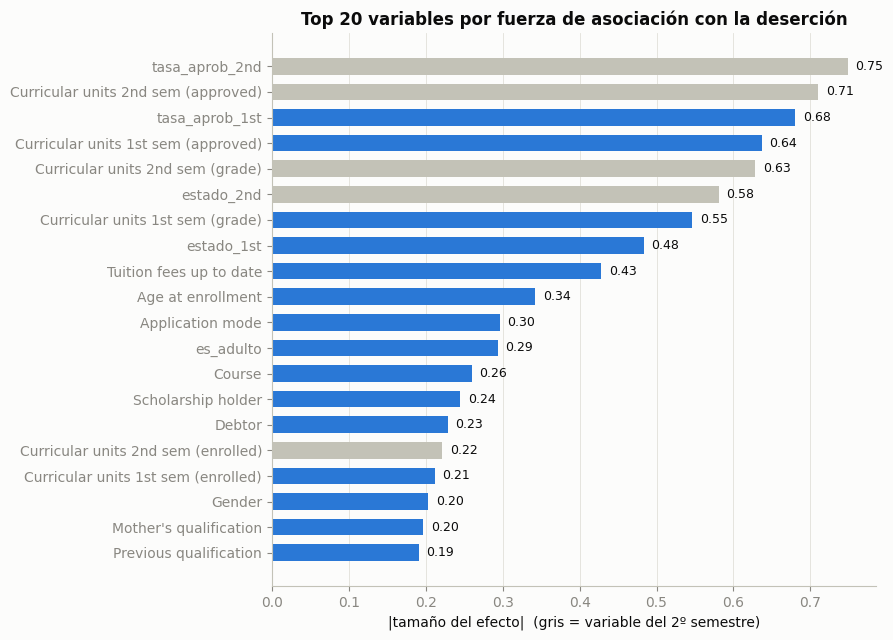

In [14]:
top = asociacion.head(20).iloc[::-1]
es_2do = top.index.str.contains("2nd")
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(top.index, top["|efecto|"], color=np.where(es_2do, "#c3c2b7", AZUL), height=0.65)
for i, v in enumerate(top["|efecto|"]):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=9, color=TINTA)
ax.set_title("Top 20 variables por fuerza de asociación con la deserción")
ax.set_xlabel("|tamaño del efecto|  (gris = variable del 2º semestre)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Hallazgos**

- **Las académicas dominan.** Las 8 variables más asociadas son de desempeño académico. La más fuerte es la tasa de aprobación (`tasa_aprob_2nd` 0,75 y `tasa_aprob_1st` 0,68).
- **Disponibles al cierre del 1er semestre** (barras azules), el orden es:
  1. `tasa_aprob_1st` (0,68)
  2. materias aprobadas (0,64)
  3. nota del 1er semestre (0,55)
  4. `estado_1st` (0,48)
  5. **`Tuition fees up to date` (0,43)**, la variable no académica más fuerte
  6. edad (0,34)
  7. modo de ingreso (0,30)
  8. curso (0,26)
  9. beca (0,24)
  10. deuda (0,23)
- **Sin relación con la deserción** (p > 0,05): inflación, desempleo, `credited` en ambos semestres, `Nacionality` e `International`. Son candidatas a eliminar.
- **Información mutua:** confirma el mismo orden general, así que el ranking no depende del método.

### 3.2 Tasa de deserción en las variables binarias

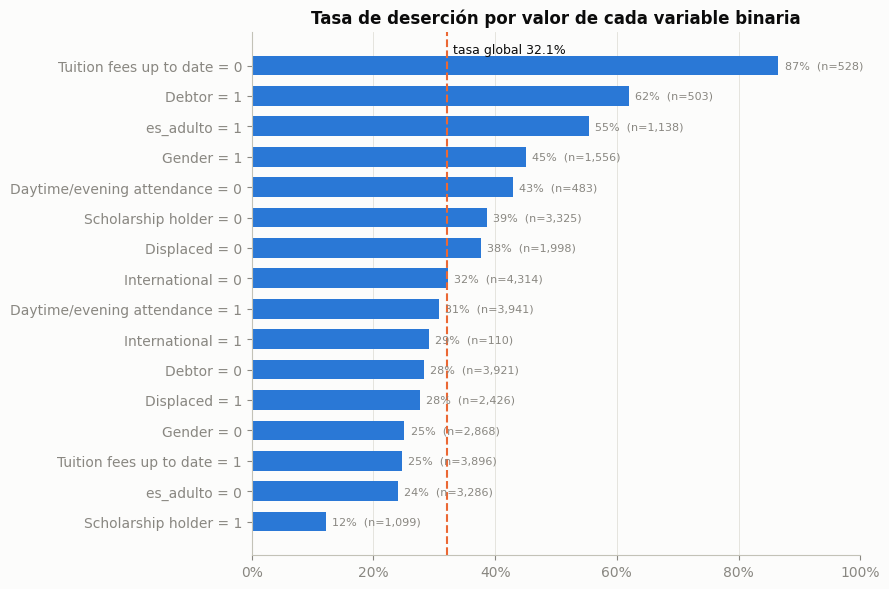

In [15]:
filas = []
for c in binarias:
    for valor, tasa in df.groupby(c)["dropout"].mean().items():
        filas.append((f"{c} = {valor}", tasa, (df[c] == valor).sum()))
tasas_bin = pd.DataFrame(filas, columns=["grupo", "tasa", "n"]).sort_values("tasa")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(tasas_bin["grupo"], tasas_bin["tasa"], color=AZUL, height=0.65)
ax.axvline(TASA_GLOBAL, color=NARANJA, linewidth=1.5, linestyle="--")
ax.text(TASA_GLOBAL + 0.01, len(tasas_bin) - 0.6, f"tasa global {TASA_GLOBAL:.1%}", color=TINTA, fontsize=9)
for i, (t, n) in enumerate(zip(tasas_bin["tasa"], tasas_bin["n"])):
    ax.text(t + 0.01, i, f"{t:.0%}  (n={n:,})", va="center", fontsize=8, color=GRIS)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Tasa de deserción por valor de cada variable binaria")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Hallazgos** (tasa global 32,1%)

- **Matrícula atrasada:** 87% de deserción, frente a 25% de quienes están al día. Es la señal no académica más fuerte del dataset.
- **Deudores:** 62% frente a 28%.
- **Adultos (25 años o más):** 55% frente a 24%.
- **Hombres** (`Gender = 1` en el diccionario de UCI): 45% frente a 25% de las mujeres.
- **Becados:** desertan mucho menos, 12% frente a 39%.
- **Jornada nocturna** (`Daytime/evening attendance = 0`): 43% frente a 31% en la diurna.
- **Desplazados:** desertan menos, 28% frente a 38%.
- **`International`:** no muestra diferencia (29% frente a 32%).

### 3.3 Variables numéricas: desertores vs. resto

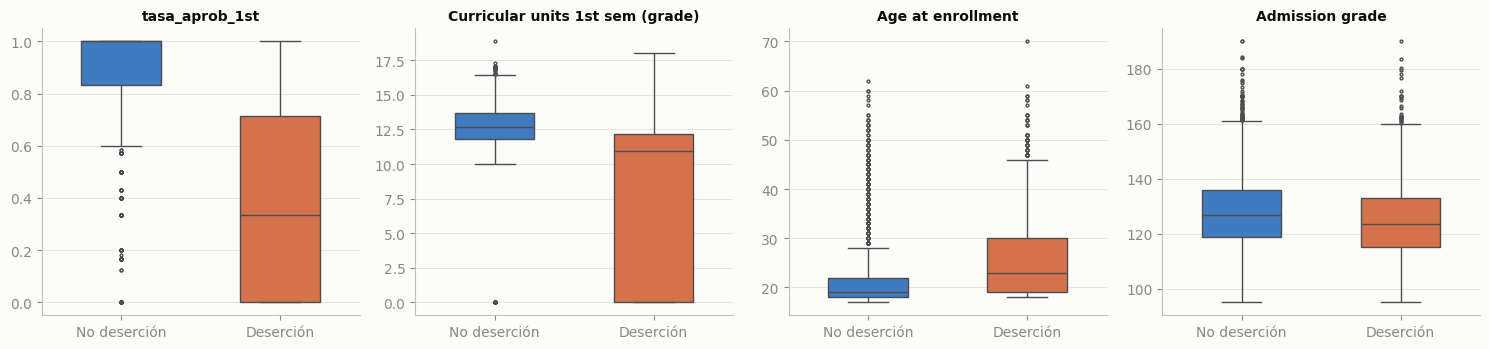

,tasa_aprob_1st,Curricular units 1st sem (grade),Age at enrollment,Admission grade
dropout,,,,
0,1.00,12.71,19.0,126.7
1,0.33,10.93,23.0,123.6


In [16]:
comparar = ["tasa_aprob_1st", "Curricular units 1st sem (grade)", "Age at enrollment", "Admission grade"]
etiquetas = df["dropout"].map({0: "No deserción", 1: "Deserción"})
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, c in zip(axes, comparar):
    sns.boxplot(x=etiquetas, y=df[c], hue=etiquetas, order=["No deserción", "Deserción"],
                palette={"No deserción": AZUL, "Deserción": NARANJA}, width=0.5,
                fliersize=2, linewidth=1, legend=False, ax=ax)
    ax.set_title(c, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

df.groupby("dropout")[comparar].median().round(2)

**Hallazgos** (medianas: no deserción vs. deserción)

- **Tasa de aprobación del 1er semestre:** 1,00 frente a 0,33. La mitad de quienes no desertan aprobó todo, mientras que la mitad de los desertores aprobó un tercio o menos.
- **Nota del 1er semestre:** 12,7 frente a 10,9. En los desertores la caja llega hasta 0 (quienes no aprobaron nada).
- **Edad de ingreso:** 19 frente a 23 años. Los desertores son mayores, y su rango intercuartílico (19 a 30) es mucho más amplio.
- **Nota de admisión:** 126,7 frente a 123,6. La diferencia es pequeña: lo que mejor anticipa la deserción es cómo le va al estudiante en la universidad, no cómo entró.

### 3.4 Deserción por curso

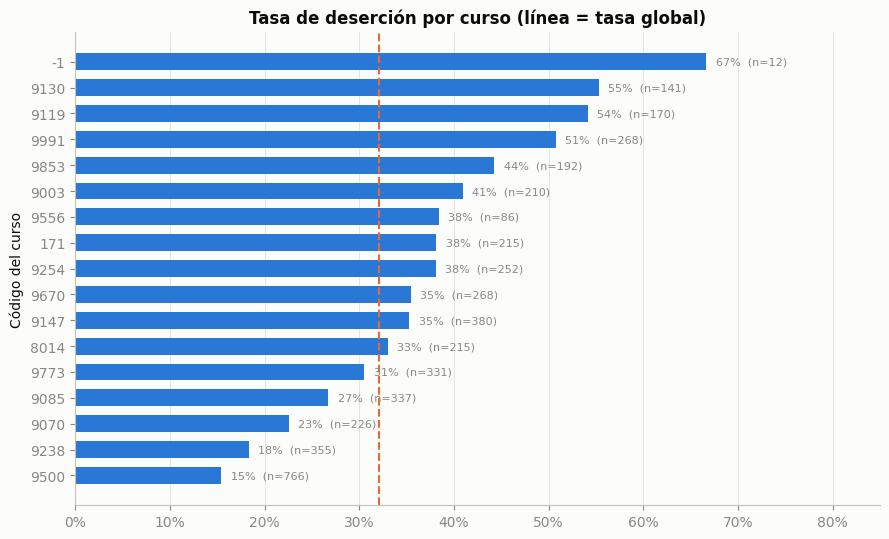

In [17]:
por_curso = (df.groupby("Course", observed=True)["dropout"]
             .agg(tasa="mean", n="size").sort_values("tasa"))
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(por_curso.index.astype(str), por_curso["tasa"], color=AZUL, height=0.65)
ax.axvline(TASA_GLOBAL, color=NARANJA, linewidth=1.5, linestyle="--")
for i, (t, n) in enumerate(zip(por_curso["tasa"], por_curso["n"])):
    ax.text(t + 0.01, i, f"{t:.0%}  (n={n})", va="center", fontsize=8, color=GRIS)
ax.set_xlim(0, 0.85)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Tasa de deserción por curso (línea = tasa global)")
ax.set_ylabel("Código del curso")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Hallazgos**

La deserción varía de **15% a 55% según el curso**. Nombres según el diccionario de UCI:

- **Menor deserción:** Enfermería (9500, 15%) y Servicio Social (9238, 18%).
- **Mayor deserción:** Equinocultura (9130, 55%), Ingeniería Informática (9119, 54%) y Gestión nocturna (9991, 51%).

El grupo `-1` (cursos agrupados) tiene solo 12 estudiantes, así que su 67% no es confiable. El curso es una variable útil para el modelo y para segmentar la atención.

## 4. Validación de las variables creadas en la limpieza

### 4.1 `estado_1st` y `estado_2nd`

In [18]:
for e in estados:
    display(df.groupby(e)["dropout"].agg(tasa_desercion="mean", n="size").round(3))

# Vista de 3 clases: composición de cada estado del 1er semestre
pd.crosstab(df["estado_1st"], df["Target"], normalize="index").round(3)

,tasa_desercion,n
estado_1st,,
evaluado_sin_aprobar,0.878,369
inscrito_sin_eval,1.000,169
no_inscrito,0.428,180
normal,0.230,3706


,tasa_desercion,n
estado_2nd,,
evaluado_sin_aprobar,0.917,469
inscrito_sin_eval,0.995,221
no_inscrito,0.428,180
normal,0.195,3554


Target,Dropout,Enrolled,Graduate
estado_1st,,,
evaluado_sin_aprobar,0.878,0.117,0.005
inscrito_sin_eval,1.000,0.000,0.000
no_inscrito,0.428,0.156,0.417
normal,0.230,0.195,0.575


In [19]:
# ¿Quiénes son los 'no_inscrito'?
no_inscritos = df[df["estado_1st"] == "no_inscrito"]
print("Cursos de los no_inscrito:", no_inscritos["Course"].value_counts()[lambda s: s > 0].to_dict())
print("Estado en el 2º semestre:", no_inscritos["estado_2nd"].value_counts().to_dict())
print("Estudiantes del curso 171 por estado:", df.loc[df["Course"] == 171, "estado_1st"].value_counts().to_dict())
pd.crosstab(no_inscritos["Course"], no_inscritos["Target"])[lambda t: t.sum(axis=1) > 0]

Cursos de los no_inscrito: {171: 180}
Estado en el 2º semestre: {'no_inscrito': 180}
Estudiantes del curso 171 por estado: {'no_inscrito': 180, 'normal': 35}


Target,Dropout,Enrolled,Graduate
Course,,,
171,77,28,75


**Hallazgos**

- **`estado_1st` funciona muy bien:**
  - `normal`: 23% de deserción.
  - `evaluado_sin_aprobar`: 87,8% (y solo 0,5% se gradúa).
  - `inscrito_sin_eval`: **100%**. Los 169 casos desertaron, así que la variable es un predictor perfecto para ese grupo.
- **Problema de datos en `no_inscrito`:**
  - Los 180 casos son **todos del curso 171** (Diseño de Animación y Multimedia), con 0 materias en ambos semestres.
  - Aun así, el 41,7% se graduó, lo que no tiene sentido si de verdad no inscribieron nada.
  - Solo 35 de los 215 estudiantes de ese curso tienen registro académico.
  - Lo más probable es que **falte el registro curricular de ese curso**, no que los estudiantes no se hayan inscrito.
- **Recomendación:** tratar esta categoría como "sin registro curricular". Para estos estudiantes, los ceros de las variables académicas son datos faltantes, no valores reales. Hay que comunicarlo al equipo de limpieza.

### 4.2 `tasa_aprob_1st` vs. materias aprobadas, y `es_adulto` vs. edad

In [20]:
comparacion = ["tasa_aprob_1st", "Curricular units 1st sem (approved)",
               "es_adulto", "Age at enrollment"]
asociacion.loc[comparacion, ["tipo", "|efecto|", "info_mutua"]].round(3)

,tipo,|efecto|,info_mutua
variable,,,
tasa_aprob_1st,numérica,0.680,0.182
Curricular units 1st sem (approved),numérica,0.637,0.174
es_adulto,categórica,0.293,0.041
Age at enrollment,numérica,0.342,0.048


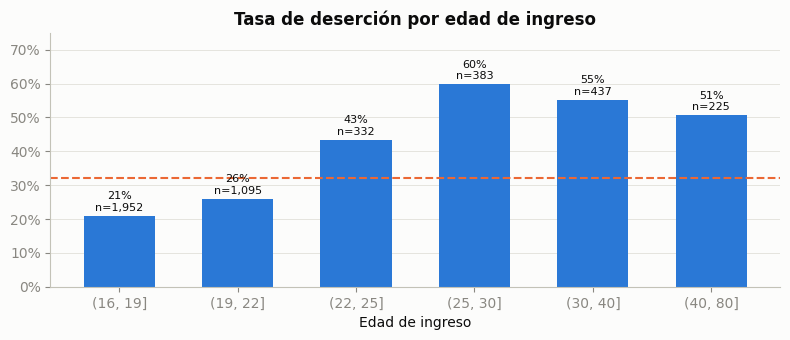

In [21]:
# La relación edad-deserción no es lineal: se mira por tramos
tramos = pd.cut(df["Age at enrollment"], [16, 19, 22, 25, 30, 40, 80])
por_edad = df.groupby(tramos, observed=True)["dropout"].agg(tasa="mean", n="size")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(por_edad.index.astype(str), por_edad["tasa"], color=AZUL, width=0.6)
ax.axhline(TASA_GLOBAL, color=NARANJA, linewidth=1.5, linestyle="--")
for i, (t, n) in enumerate(zip(por_edad["tasa"], por_edad["n"])):
    ax.text(i, t + 0.015, f"{t:.0%}\nn={n:,}", ha="center", fontsize=8, color=TINTA)
ax.set_ylim(0, 0.75)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Tasa de deserción por edad de ingreso")
ax.set_xlabel("Edad de ingreso")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Hallazgos**

- **`tasa_aprob_1st` sí aporta.** Tiene más asociación que las materias aprobadas en bruto (0,68 frente a 0,64, y mayor información mutua). Ambas están muy correlacionadas (0,83, ver sección 5), así que en el modelo basta con la tasa.
- **`es_adulto` resume bien la edad, pero la edad sigue siendo mejor** (0,34 frente a 0,29). La relación no es lineal:
  - La deserción sube de 21% (17 a 19 años) a **60% (26 a 30 años)**, y luego baja un poco (51% después de los 40).
  - El tramo de 23 a 25 años ya está en 43%, así que un corte en 23 años podría separar mejor que el de 25.
  - Conviene conservar la edad continua y dejar el flag como opcional.

## 5. Redundancia y multicolinealidad

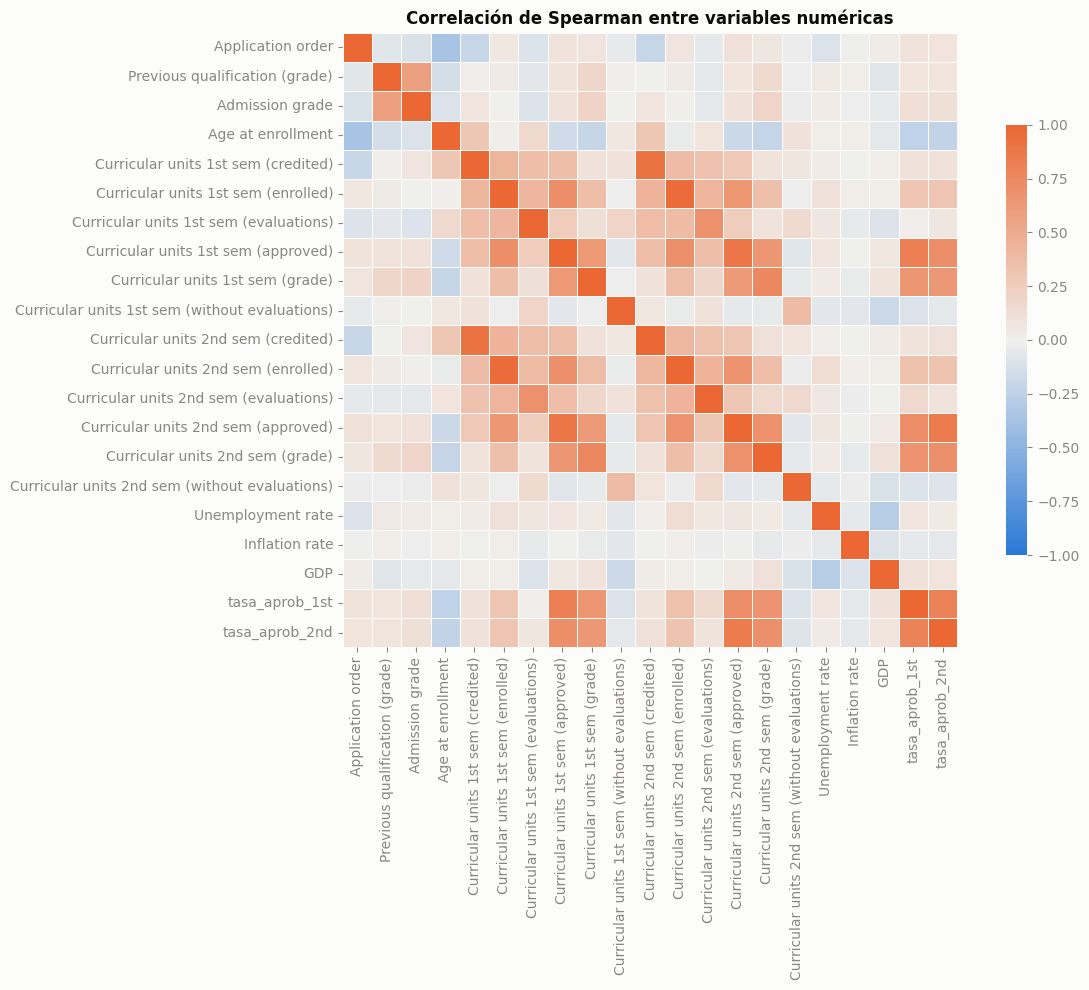

In [22]:
corr = df[numericas].corr(method="spearman")
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, cmap=MAPA_DIVERGENTE, vmin=-1, vmax=1, center=0, square=True,
            linewidths=0.5, linecolor="#fcfcfb", cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Correlación de Spearman entre variables numéricas")
ax.grid(False)
plt.tight_layout()
plt.show()

In [23]:
pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("spearman").reset_index())
pares[pares["spearman"].abs() > 0.7].sort_values("spearman", key=abs, ascending=False).round(3)

,level_0,level_1,spearman
95,Curricular units 1st sem (enrolled),Curricular units 2nd sem (enrolled),0.962
79,Curricular units 1st sem (credited),Curricular units 2nd sem (credited),0.914
124,Curricular units 1st sem (approved),Curricular units 2nd sem (approved),0.892
188,Curricular units 2nd sem (approved),tasa_aprob_2nd,0.858
130,Curricular units 1st sem (approved),tasa_aprob_1st,0.827
209,tasa_aprob_1st,tasa_aprob_2nd,0.798
137,Curricular units 1st sem (grade),Curricular units 2nd sem (grade),0.762
187,Curricular units 2nd sem (approved),tasa_aprob_1st,0.719
131,Curricular units 1st sem (approved),tasa_aprob_2nd,0.717
91,Curricular units 1st sem (enrolled),Curricular units 1st sem (approved),0.707


In [24]:
# Nacionality (ya agrupada) e International
pd.crosstab(df["Nacionality"], df["International"])

International,0,1
Nacionality,,
-1,0,110
1,4314,0


**Hallazgos**

- **El 2º semestre repite al 1er semestre.** Materias inscritas (0,96), convalidadas (0,91), aprobadas (0,89) y nota (0,76) están muy correlacionadas entre semestres. Es otra razón para prescindir del 2º semestre (ver sección 7): aporta poca información nueva.
- **Redundancia dentro del 1er semestre:**
  - `approved` y `tasa_aprob_1st`: 0,83.
  - `enrolled` y `approved`: 0,71.
  - Para cada grupo basta un representante: `tasa_aprob_1st`, nota, `enrolled` y `estado_1st`.
- **`Nacionality` e `International` son la misma variable.** Tras la agrupación, `Nacionality = -1` coincide exactamente con `International = 1` (110 casos). Ninguna se asocia con la deserción, así que se pueden eliminar ambas. Así lo describe el informe, aunque el CSV limpio todavía las tiene.
- **Variables macroeconómicas:** apenas se correlacionan con el resto (son la cohorte).

## 6. Interacciones y perfiles de riesgo

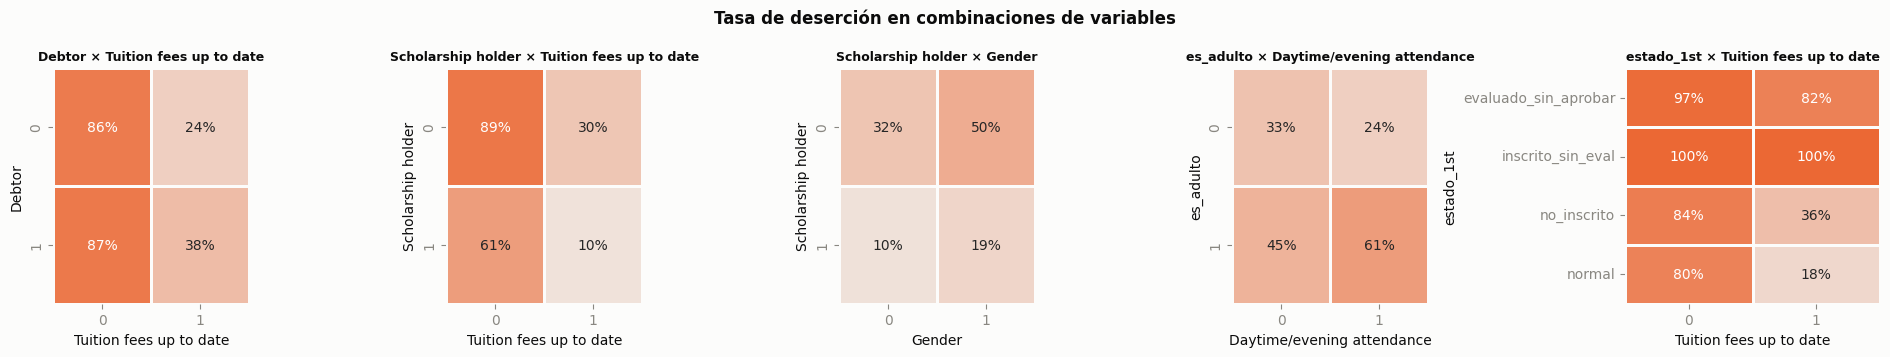

In [25]:
def tasa_cruzada(fila, columna):
    return df.pivot_table(index=fila, columns=columna, values="dropout",
                          aggfunc="mean", observed=True)


cruces = [("Debtor", "Tuition fees up to date"),
          ("Scholarship holder", "Tuition fees up to date"),
          ("Scholarship holder", "Gender"),
          ("es_adulto", "Daytime/evening attendance"),
          ("estado_1st", "Tuition fees up to date")]

fig, axes = plt.subplots(1, 5, figsize=(19, 3.6), gridspec_kw={"width_ratios": [1, 1, 1, 1, 1.3]})
for ax, (fila, columna) in zip(axes, cruces):
    sns.heatmap(tasa_cruzada(fila, columna), annot=True, fmt=".0%", vmin=0, vmax=1,
                cmap=LinearSegmentedColormap.from_list("seq", ["#f0efec", NARANJA]),
                cbar=False, linewidths=2, linecolor="#fcfcfb", ax=ax)
    ax.set_title(f"{fila} × {columna}", fontsize=9)
    ax.grid(False)
fig.suptitle("Tasa de deserción en combinaciones de variables", fontweight="bold")
plt.tight_layout()
plt.show()

In [26]:
# Tamaño de cada celda, para no sacar conclusiones de grupos muy pequeños
for fila, columna in cruces:
    display(pd.crosstab(df[fila], df[columna]).rename_axis(index=fila, columns=columna))

Tuition fees up to date,0,1
Debtor,,
0,282,3639
1,246,257


Tuition fees up to date,0,1
Scholarship holder,,
0,482,2843
1,46,1053


Gender,0,1
Scholarship holder,,
0,2001,1324
1,867,232


Daytime/evening attendance,0,1
es_adulto,,
0,78,3208
1,405,733


Tuition fees up to date,0,1
estado_1st,,
evaluado_sin_aprobar,146,223
inscrito_sin_eval,40,129
no_inscrito,25,155
normal,317,3389


In [27]:
perfiles = {
    "Matrícula al día y sin deuda": (df["Tuition fees up to date"] == 1) & (df["Debtor"] == 0),
    "Matrícula atrasada": df["Tuition fees up to date"] == 0,
    "Becado con matrícula al día": (df["Scholarship holder"] == 1) & (df["Tuition fees up to date"] == 1),
    "Adulto (25+) en jornada diurna": (df["es_adulto"] == 1) & (df["Daytime/evening attendance"] == 1),
    "Evaluado sin aprobar en el 1er semestre": df["estado_1st"] == "evaluado_sin_aprobar",
    "1er semestre normal, aprobó menos de la mitad": (df["estado_1st"] == "normal") & (df["tasa_aprob_1st"] < 0.5),
}
pd.DataFrame([(nombre, m.sum(), df.loc[m, "dropout"].mean()) for nombre, m in perfiles.items()],
             columns=["perfil", "n", "tasa_desercion"]).sort_values("tasa_desercion").round(3)

,perfil,n,tasa_desercion
2,Becado con matrícula al día,1053,0.101
0,Matrícula al día y sin deuda,3639,0.238
3,Adulto (25+) en jornada diurna,733,0.614
5,"1er semestre normal, aprobó menos de la mitad",310,0.729
1,Matrícula atrasada,528,0.866
4,Evaluado sin aprobar en el 1er semestre,369,0.878


**Hallazgos**

- **El atraso en la matrícula domina sobre todo lo demás.** Con matrícula atrasada, la deserción es de 86 a 87% haya o no deuda. La deuda solo diferencia a quienes están al día (24% frente a 38%).
- **La beca protege, pero no contra el atraso.** Un becado al día deserta 10%, pero si se atrasa sube a 61% (solo 46 casos, conviene leerlo con cautela).
- **Género y beca:** un hombre sin beca deserta 50%, mientras que una mujer becada deserta 10%.
- **Edad y jornada:** los adultos en jornada **diurna** desertan más (61%) que los adultos en jornada nocturna (45%). La jornada nocturna parece acomodarse mejor a quienes trabajan. En los jóvenes pasa lo contrario (24% diurna frente a 33% nocturna).
- **Rendimiento y matrícula se suman:** con un 1er semestre normal y matrícula al día, la deserción es de 18%. Con un 1er semestre normal pero matrícula atrasada, sube a 80%.

**Perfiles de riesgo** (tasa global 32%)

| Perfil | n | Deserción |
|---|---|---|
| Evaluado sin aprobar en el 1er semestre | 369 | 88% |
| Matrícula atrasada | 528 | 87% |
| 1er semestre normal, pero aprobó menos de la mitad | 310 | 73% |
| Adulto (25+) en jornada diurna | 733 | 61% |
| Matrícula al día y sin deuda | 3.639 | 24% |
| Becado con matrícula al día | 1.053 | 10% |

## 7. Fuga de información: variables del 2º semestre

Si la predicción se hace al cierre del 1er semestre, el 2º semestre aún no ha ocurrido. Para medir cuánto "inflan" esas variables el desempeño, se entrena el mismo modelo de referencia (random forest, validación cruzada estratificada de 5 particiones, métrica ROC-AUC) con tres conjuntos de variables. No es el modelo final: solo sirve para comparar conjuntos de variables.

In [28]:
X = pd.get_dummies(df.drop(columns=["Target", "dropout"]), columns=estados)
y = df["dropout"]

vars_2do = [c for c in X.columns if "2nd" in c]
vars_academicas = [c for c in X.columns if "sem" in c or "estado" in c or "tasa_aprob" in c]
conjuntos = {
    "Solo datos de ingreso": X.drop(columns=vars_academicas),
    "Hasta el 1er semestre": X.drop(columns=vars_2do),
    "Con el 2º semestre": X,
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
modelo = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
auc = {nombre: cross_val_score(modelo, Xc, y, cv=cv, scoring="roc_auc")
       for nombre, Xc in conjuntos.items()}
resultado_fuga = pd.DataFrame({"variables": [Xc.shape[1] for Xc in conjuntos.values()],
                               "auc_media": [a.mean() for a in auc.values()],
                               "auc_desv": [a.std() for a in auc.values()]},
                              index=auc.keys()).round(3)
resultado_fuga

,variables,auc_media,auc_desv
Solo datos de ingreso,24,0.811,0.014
Hasta el 1er semestre,35,0.902,0.008
Con el 2º semestre,46,0.925,0.009


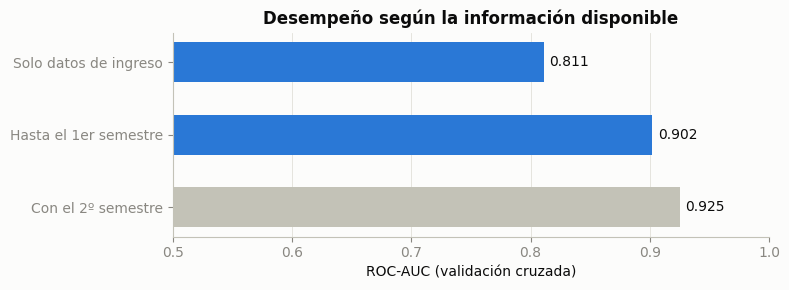

In [29]:
fig, ax = plt.subplots(figsize=(8, 3))
colores = [AZUL, AZUL, "#c3c2b7"]
ax.barh(resultado_fuga.index[::-1], resultado_fuga["auc_media"][::-1], color=colores[::-1], height=0.55)
for i, v in enumerate(resultado_fuga["auc_media"][::-1]):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", color=TINTA)
ax.set_xlim(0.5, 1)
ax.set_xlabel("ROC-AUC (validación cruzada)")
ax.set_title("Desempeño según la información disponible")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Hallazgos**

| Información disponible | Variables | ROC-AUC |
|---|---|---|
| Solo datos de ingreso | 24 | 0,811 |
| Hasta el 1er semestre | 35 | 0,902 |
| Con el 2º semestre | 46 | 0,925 |

- **El 1er semestre aporta mucho** (+0,091 de AUC sobre los datos de ingreso). **El 2º semestre aporta poco** (+0,023), porque en gran parte repite la información del 1er semestre (sección 5).
- **Decisión:** para responder la pregunta de negocio (priorizar al cierre del 1er semestre), el modelo debe usar **solo variables disponibles hasta el 1er semestre**. Se pierde muy poco desempeño y se evita entrenar con información que en la práctica no existe en ese momento.
- **Pregunta abierta:** el dataset no indica en qué momento se miden `Tuition fees up to date`, `Debtor` y `Scholarship holder`. Si se registran al final de la carrera y no al cierre del 1er semestre, también serían fuga. Esto debería aclararse en el informe o tratarse como supuesto.

## 8. Conclusiones

### Resumen de patrones

1. **El desempeño académico del 1er semestre es el principal predictor.** Tasa de aprobación, nota y `estado_1st` son las variables más fuertes. Quien no aprueba nada en el 1er semestre deserta en casi 9 de cada 10 casos.
2. **El atraso en la matrícula es la señal no académica más fuerte:** 87% de deserción frente a 25%, con o sin deuda.
3. **Factores de riesgo adicionales:** ser adulto (sobre todo de 26 a 30 años), estudiar en jornada diurna siendo adulto, ser hombre, no tener beca, tener deuda y el curso (de 15% a 55% según el programa).
4. **Las condiciones de ingreso pesan poco.** La nota de admisión y la formación previa casi no discriminan. Con solo datos de ingreso el modelo llega a AUC 0,81. Al agregar el 1er semestre sube a 0,90.

### Recomendaciones para el modelamiento

- **Variables:** usar solo información hasta el 1er semestre y excluir todas las del 2º semestre.
  - Eliminar `Nacionality`, `International` y `credited` (sin asociación) y una de cada par redundante (por ejemplo, `approved` frente a `tasa_aprob_1st`).
  - Tratar las variables macroeconómicas como cohorte, o evaluar si se excluyen.
- **Target:** la vista binaria (deserción vs. resto) es la que responde la pregunta de negocio. Si se mantienen 3 clases, `Enrolled` (17,9%) será la clase más difícil.
- **Desbalance:** partición estratificada, `class_weight` y métricas como recall de deserción y PR-AUC, no *accuracy*.
- **Línea base:** un random forest sin ajustar ya obtiene AUC 0,90 con variables hasta el 1er semestre. Los modelos que se comparen deben superarlo.

### Siguientes pasos

- `no_inscrito` corresponde por completo al curso 171 y parece un **registro curricular faltante**, no estudiantes sin inscripción. Sus ceros académicos deberían tratarse como faltantes.
- El informe dice que se eliminaron `Nacionality` e `International`, pero el CSV limpio todavía las incluye.
- Hay que confirmar en qué momento se miden `Tuition fees up to date`, `Debtor` y `Scholarship holder` (posible fuga de información).